# Risco de Crédito: KNN x Árvore de Decisão

Projeto avaliativo do Módulo 1 (Machine Learning e Visão Computacional, T3).

Escolhi a Opção A, a base `credit_risk_dataset.csv`, com 32.581 pedidos de empréstimo e 12 colunas.

O banco quer saber, antes de liberar o empréstimo, se o cliente vai ficar inadimplente (`loan_status = 1`) ou
pagar em dia (`loan_status = 0`). O modelo pode errar de dois jeitos:

- Falso positivo: marca como arriscado um cliente que pagaria. O banco recusa e deixa de ganhar os juros.
- Falso negativo: marca como seguro um cliente que não paga. O banco empresta e perde o dinheiro.

O notebook segue as 6 fases do enunciado. Fui explicando cada decisão nas células de texto.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
from imblearn.over_sampling import SMOTENC

import os
SEED = 42                      # semente fixa para dar sempre o mesmo resultado
FIG_DIR = "reports/figures"    # salvo os gráficos aqui para usar no README
os.makedirs(FIG_DIR, exist_ok=True)

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

## Fase 1: Análise Exploratória de Dados (EDA)

### 1.1 Descritiva e estatística

In [2]:
df_raw = pd.read_csv("data/credit_risk_dataset.csv")
df = df_raw.copy()

print(f"Tamanho da base: {df.shape[0]:,} linhas x {df.shape[1]} colunas")
df.head()

Tamanho da base: 32,581 linhas x 12 colunas


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.00,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.00,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.00,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.00,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.00,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [3]:
# tipos das colunas e quantos valores não nulos cada uma tem
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB


In [4]:
# estatísticas das colunas numéricas
df.describe().T

,count,mean,std,min,25%,50%,75%,max
person_age,"32,581.00",27.73,6.35,20.00,23.00,26.00,30.00,144.00
person_income,"32,581.00","66,074.85","61,983.12","4,000.00","38,500.00","55,000.00","79,200.00","6,000,000.00"
person_emp_length,"31,686.00",4.79,4.14,0.00,2.00,4.00,7.00,123.00
loan_amnt,"32,581.00","9,589.37","6,322.09",500.00,"5,000.00","8,000.00","12,200.00","35,000.00"
loan_int_rate,"29,465.00",11.01,3.24,5.42,7.90,10.99,13.47,23.22
loan_status,"32,581.00",0.22,0.41,0.00,0.00,0.00,0.00,1.00
loan_percent_income,"32,581.00",0.17,0.11,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,"32,581.00",5.80,4.06,2.00,3.00,4.00,8.00,30.00


In [5]:
# e das categóricas
df.describe(include="object").T

,count,unique,top,freq
person_home_ownership,32581,4,RENT,16446
loan_intent,32581,6,EDUCATION,6453
loan_grade,32581,7,A,10777
cb_person_default_on_file,32581,2,N,26836


In [6]:
# nulos, duplicadas e proporção do alvo
print("Valores nulos por coluna:")
print(df.isna().sum()[df.isna().sum() > 0], "\n")
print(f"Linhas duplicadas: {df.duplicated().sum()}\n")
print("Distribuição do alvo (loan_status):")
print(df["loan_status"].value_counts(normalize=True).mul(100).round(2).astype(str) + " %")

Valores nulos por coluna:
person_emp_length     895
loan_int_rate        3116
dtype: int64 

Linhas duplicadas: 165

Distribuição do alvo (loan_status):
loan_status
0    78.18 %
1    21.82 %
Name: proportion, dtype: str


In [7]:
# assimetria: perto de 0 é simétrica, acima de 1 tem cauda longa à direita
df.select_dtypes("number").drop(columns="loan_status").skew().sort_values(ascending=False).to_frame("skew")

,skew
person_income,32.87
person_emp_length,2.61
person_age,2.58
cb_person_cred_hist_length,1.66
loan_amnt,1.19
loan_percent_income,1.06
loan_int_rate,0.21


### 1.2 Análise visual

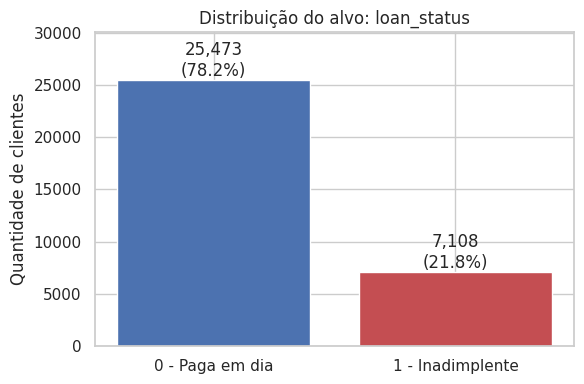

In [8]:
# gráfico 1: quantos clientes tem em cada classe
fig, ax = plt.subplots(figsize=(6, 4))
cont = df["loan_status"].value_counts().sort_index()
bars = ax.bar(["0 - Paga em dia", "1 - Inadimplente"], cont.values, color=["#4C72B0", "#C44E52"])
for b, v in zip(bars, cont.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / cont.sum():.1%})", ha="center", va="bottom")
ax.set_title("Distribuição do alvo: loan_status")
ax.set_ylabel("Quantidade de clientes")
ax.set_ylim(0, cont.max() * 1.18)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/01_alvo_desbalanceado.png", dpi=110); plt.show()

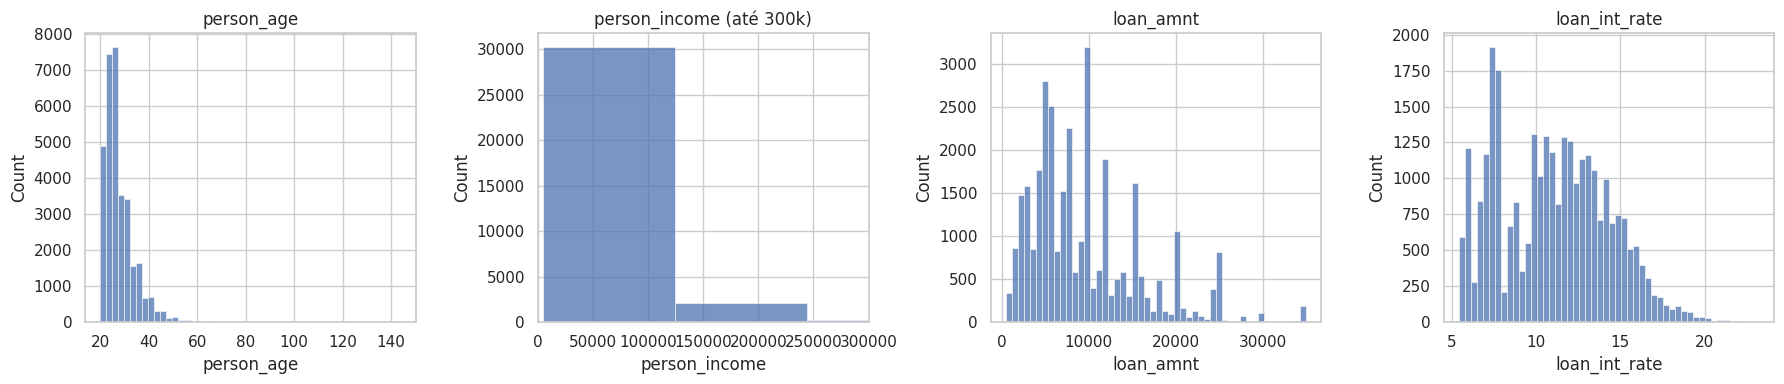

In [9]:
# gráfico 2: histogramas das principais numéricas
cols = ["person_age", "person_income", "loan_amnt", "loan_int_rate"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, cols):
    sns.histplot(df[c].dropna(), bins=50, ax=ax, color="#4C72B0")
    ax.set_title(c)
axes[1].set_xlim(0, 300_000)  # cortei em 300 mil, senão não dá para ver nada
axes[1].set_title("person_income (até 300k)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/02_histogramas.png", dpi=110); plt.show()

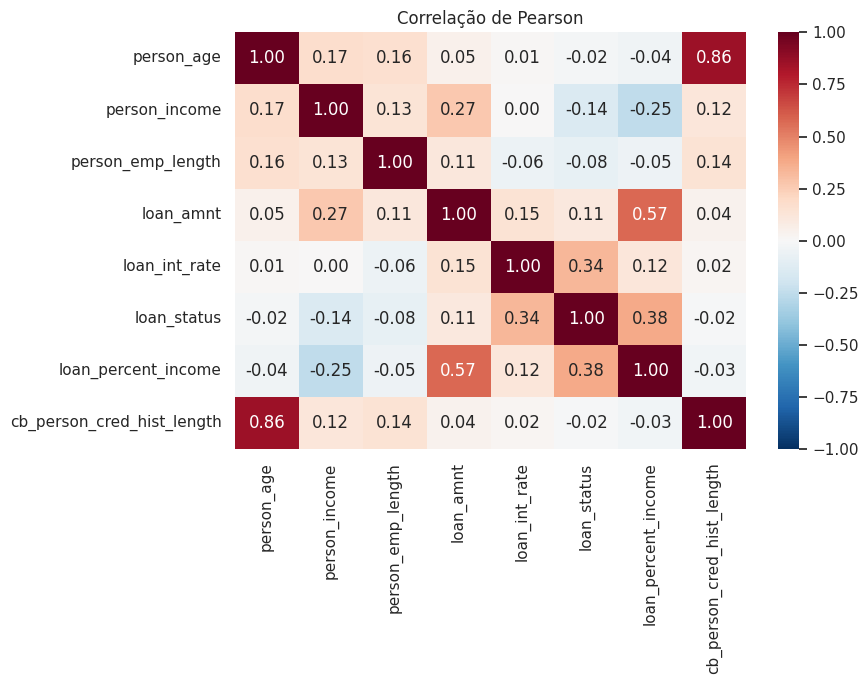

In [10]:
# gráfico 3: correlação de Pearson
fig, ax = plt.subplots(figsize=(9, 7))
corr = df.select_dtypes("number").corr(method="pearson")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlação de Pearson")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/03_correlacao.png", dpi=110); plt.show()

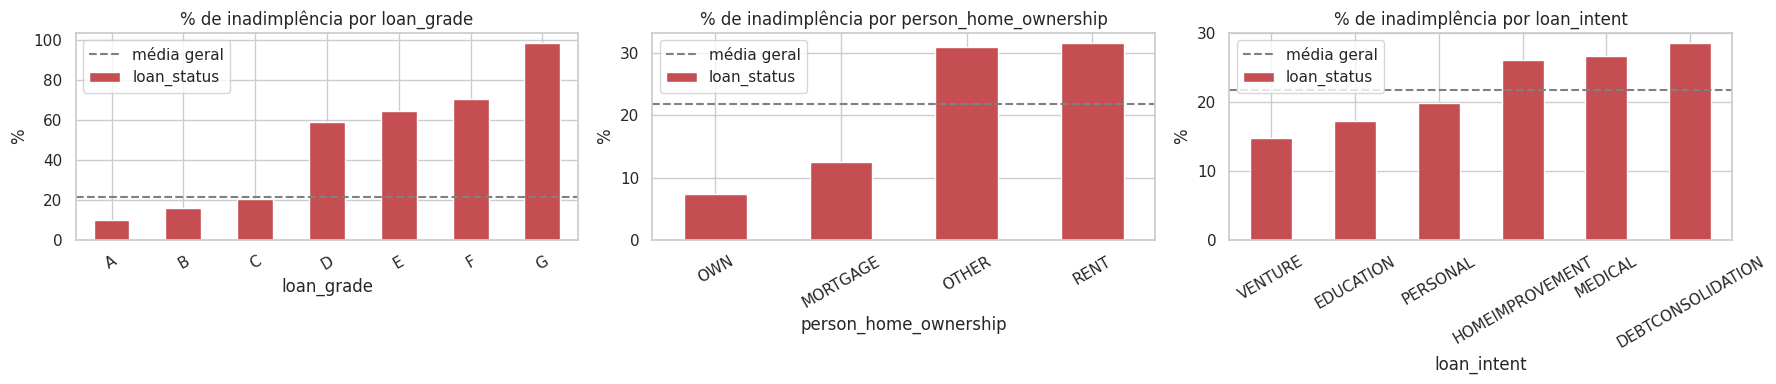

In [11]:
# gráfico 4: inadimplência por categoria (as categóricas não entram no Pearson)
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, c in zip(axes, ["loan_grade", "person_home_ownership", "loan_intent"]):
    taxa = df.groupby(c)["loan_status"].mean().sort_values() if c != "loan_grade" \
        else df.groupby(c)["loan_status"].mean()
    taxa.mul(100).plot(kind="bar", ax=ax, color="#C44E52")
    ax.axhline(df["loan_status"].mean() * 100, ls="--", color="gray", label="média geral")
    ax.set_title(f"% de inadimplência por {c}"); ax.set_ylabel("%"); ax.legend()
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/04_inadimplencia_categorias.png", dpi=110); plt.show()

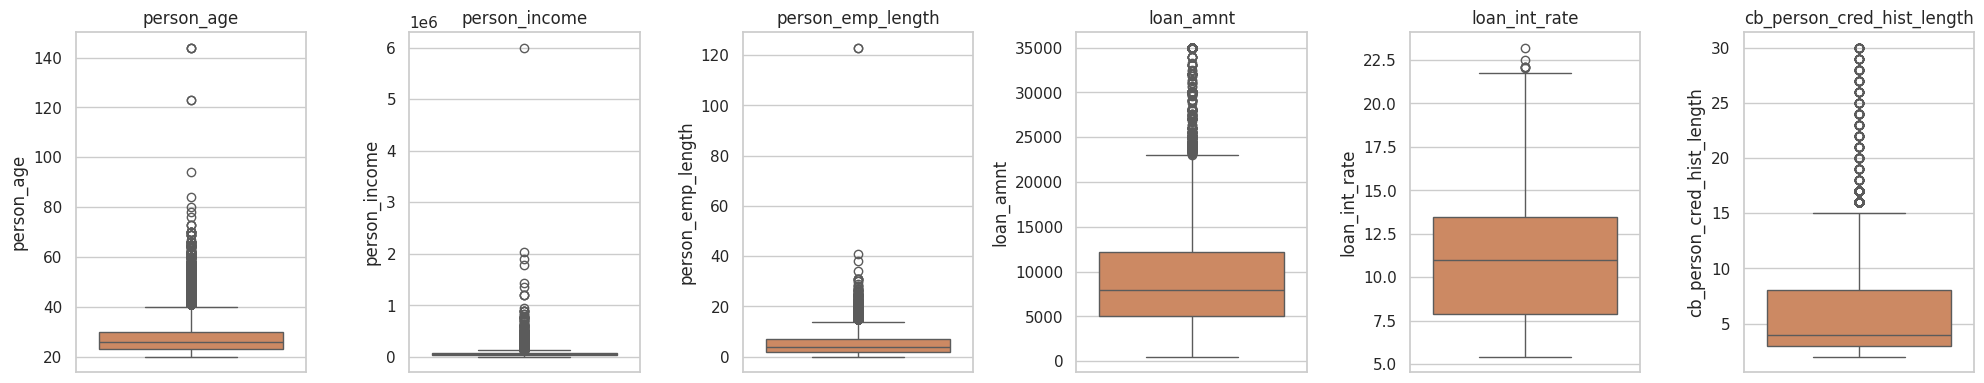

In [12]:
# gráfico 5: boxplots para ver os outliers
cols = ["person_age", "person_income", "person_emp_length", "loan_amnt", "loan_int_rate", "cb_person_cred_hist_length"]
fig, axes = plt.subplots(1, 6, figsize=(20, 4))
for ax, c in zip(axes, cols):
    sns.boxplot(y=df[c], ax=ax, color="#DD8452")
    ax.set_title(c)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/05_boxplots.png", dpi=110); plt.show()

### 1.3 Tomada de decisão: o que a EDA mostrou

A base tem 32.581 linhas e 12 colunas, sendo 8 numéricas e 4 categóricas.

O alvo é desbalanceado: 78,2% pagam em dia e 21,8% ficam inadimplentes. Se eu fizesse um modelo que aprova todo
mundo, ele teria 78% de acurácia e não serviria para nada. Então não vou me guiar pela acurácia. Vou olhar recall,
precisão e F1 da classe 1, e vou balancear as classes, mas só no treino.

No `describe` apareceram valores que não fazem sentido: idade de 144 anos e 123 anos de emprego. Isso é erro de
digitação. Já a renda vai até 6 milhões com mediana de 55 mil. Esse caso é diferente, porque deve ser gente que
ganha muito mesmo, mas uma cauda desse tamanho atrapalha o KNN e vou ter que tratar. Também tem nulos em
`loan_int_rate` (3.116) e em `person_emp_length` (895), além de 165 linhas duplicadas.

Nos gráficos, o que mais me chamou atenção:

- A coluna mais correlacionada com a inadimplência é `loan_percent_income` (0,38), que é quanto o empréstimo pesa
  na renda. Depois vem a taxa de juros (0,34). A renda tem correlação negativa (-0,14).
- O `loan_grade` parece uma escada: uns 10% de inadimplência no grau A e 98% no G.
- Quem aluga (RENT) tem uns 32% de inadimplência, e quem tem casa própria (OWN) fica em 7%.
- `person_age` e `cb_person_cred_hist_length` são bem correlacionadas entre si (0,86), o que é esperado. Deixei as
  duas porque não são a mesma coisa.

O que vou fazer a partir disso: tirar as duplicadas e as linhas com valores impossíveis, preencher os nulos
olhando a distribuição de cada coluna, tratar a cauda da renda só para o KNN, criar a coluna
`comprometimento_renda` e codificar o `loan_grade` respeitando a ordem de A até G.